# Sprint 2 — Early–late delay-locked loop (DLL)

**Sprint-2 deliverable:** a DLL that tracks a stable delay — its **S-curve** and a **tracking run**.

**What and why.** The batch MLE needs a whole block of data and a search over all delays. Real receivers (GPS, spread
spectrum) instead *track* the delay continuously with a cheap feedback loop: compare the signal slightly *early* and
slightly *late*, and nudge the estimate towards whichever side matches better. The project asks how this practical
tracker compares with the batch MLE and with the bounds.

| Step | Question it answers |
|---|---|
| 2.1 Discriminator | how does "early minus late" measure the timing error? |
| 2.2 S-curve | over what range of errors does the loop pull back correctly? |
| 2.3 Loop | how is the estimate updated, and how much noise does it average? |
| 2.4 Practical details | what must a correct implementation take care of? |
| 2.5 Tracking run | does it lock and stay locked? |
| 2.6 Steady-state jitter | how accurate is it once locked? |

## 2.1 The early–late discriminator

Let $\theta$ be the loop's current estimate and $\varepsilon=\theta-\tau$ its error. The receiver correlates the data
with two replicas, shifted by $\pm d/2$ (here $d=0.5$ chip):

$$ E=\sum_n r[n]\,s(t_n-\theta+\tfrac d2),\qquad L=\sum_n r[n]\,s(t_n-\theta-\tfrac d2). $$

Without noise, $r = s(\cdot-\tau)$ and each correlation is a sample of the signal's autocorrelation $R(h)=\sum_n
s(t_n)s(t_n-h)$:

$$ E-L = R(\varepsilon-\tfrac d2)-R(\varepsilon+\tfrac d2). $$

**Why this measures the error.** $R$ is symmetric with its peak at 0. If $\varepsilon=0$ the two replicas sit
symmetrically on either side of the peak and $E=L$. If the estimate is late ($\varepsilon>0$), the early replica is
closer to the peak, so $E>L$. A Taylor expansion around $\varepsilon=0$ gives

$$ E-L\;\approx\;-2R'(\tfrac d2)\,\varepsilon \;=\; k\,\varepsilon,\qquad k>0 \ (\text{since }R'(d/2)<0), $$

so after dividing by the slope $k$ the **discriminator** $D=(E-L)/k\approx\varepsilon$ estimates the error directly.
The function $D(\varepsilon)$ over all $\varepsilon$ is the **S-curve**.

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

## 2.2 The S-curve (Sprint-2 deliverable)
We compute the noise-free discriminator output for errors from −3 to +3 chips (averaged over all integration blocks,
see 2.4). Where $D$ has the **same sign** as $\varepsilon$, the loop pushes the estimate back towards the truth; the
range where this holds is the **pull-in range**.

slope at zero = 1.000 (should be 1 by construction); pull-in range = ±1.80 chips
peak of S-curve: D = 0.440 at ε = 0.70 chips


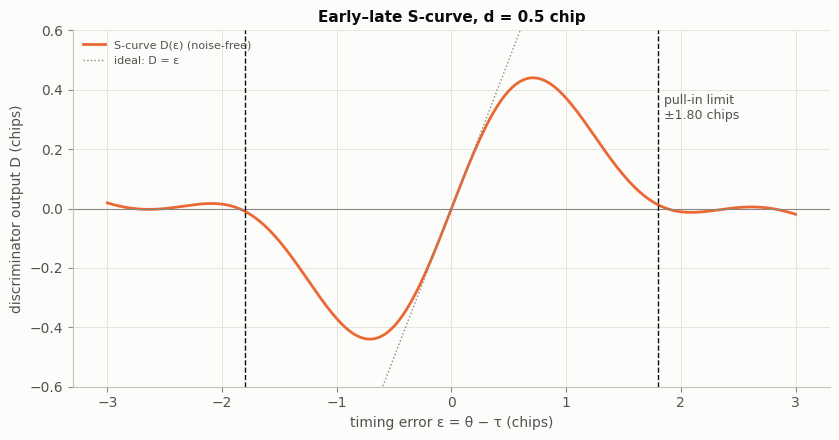

In [2]:
cfg = Config()
sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))
dll = EarlyLateDLL(cfg, sc.wave.chips)      # same pilot as the MLE, repeated periodically
rng = np.random.default_rng(2)

eps = np.linspace(-3, 3, 241)
S = dll.s_curve(eps)
pull_in = dll.pull_in_range(rng)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(eps, S, color=COLORS["dll"], label="S-curve D(ε) (noise-free)")
ax.plot(eps, eps, color=MUTED, ls=":", lw=1, label="ideal: D = ε")
ax.axhline(0, color=MUTED, lw=0.8)
for x in (-pull_in, pull_in):
    ax.axvline(x, color=COLORS["crlb"], ls="--", lw=1)
ax.text(pull_in + 0.05, 0.3, f"pull-in limit\n±{pull_in:.2f} chips", color=INK2, fontsize=9)
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel("timing error ε = θ − τ (chips)"); ax.set_ylabel("discriminator output D (chips)")
ax.set_title(f"Early–late S-curve, d = {cfg.el_spacing} chip")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s2_dll_s_curve.png")

slope = (dll.s_curve(0.01) - dll.s_curve(-0.01))[0] / 0.02
print(f"slope at zero = {slope:.3f} (should be 1 by construction); pull-in range = ±{pull_in:.2f} chips")
print(f"peak of S-curve: D = {S.max():.3f} at ε = {eps[np.argmax(S)]:.2f} chips")

## 2.3 The loop: how the estimate is updated

Every $M=4$ chips the loop computes a discriminator value $D_j$ and moves the estimate a fraction $K$ of the way:

$$ \theta_{j+1}=\theta_j-K\,D_j . $$

**Error dynamics (linear region).** With $D_j=\varepsilon_j+n_j$ (true error plus noise),

$$ \varepsilon_{j+1}=(1-K)\,\varepsilon_j-K\,n_j . $$

* **Stability:** the error decays iff $|1-K|<1$, i.e. $0<K<2$.
* **Noise averaging.** Unrolling, $\varepsilon_j$ is the noise filtered by the impulse response $h_k=K(1-K)^k$. For
  independent $n_j$ with variance $\sigma_n^2$:

$$ \operatorname{var}(\varepsilon)=\sigma_n^2\sum_{k\ge0}h_k^2=\sigma_n^2\,\frac{K^2}{1-(1-K)^2}=\sigma_n^2\,\frac{K}{2-K}. $$

  Averaging $N$ independent measurements would give $\sigma_n^2/N$, so the loop behaves like an average of
  $\boxed{N_{\rm eff}=(2-K)/K}$ updates. Equivalently, its one-sided **noise bandwidth** is
  $B_L T_I=\sum h_k^2/(2(\sum h_k)^2)=K/(2(2-K))$, the standard first-order-loop result.

**Our design choice.** We want the DLL, once locked, to average the same amount of signal as the 64-chip MLE batch:
$N_{\rm eff}=64/4=16$ updates $\Rightarrow K=2/(N_{\rm eff}+1)=2/17\approx0.118$, i.e. $1/(2B_L)=64$ chips.
This makes the *steady-state* jitter comparable with the batch CRLB. (Caveat, important later: the DLL runs for 160
updates = 640 chips in total, so overall it *sees* 10× more data than the batch. Equal jitter ≠ equal information.)

In [3]:
K = cfg.dll_gain
print(f"K = {K:.4f},  N_eff = {(2 - K) / K:.1f} updates,  B_L = {cfg.dll_bl:.5f}/chip,  "
      f"1/(2 B_L) = {1 / (2 * cfg.dll_bl):.0f} chips,  run length = {cfg.dll_n_updates} updates "
      f"= {cfg.dll_n_updates * cfg.dll_block_chips} chips")

K = 0.1176,  N_eff = 16.0 updates,  B_L = 0.00781/chip,  1/(2 B_L) = 64 chips,  run length = 160 updates = 640 chips


## 2.4 Practical details a correct DLL needs (each one was found by testing)

| Detail | What we do | Why — what went wrong without it |
|---|---|---|
| **Acquisition** | before tracking, correlate the first 64 chips with the pilot on a 0.5-chip grid over the prior and start at the best point | a loop only pulls in from inside its pull-in range (±1.8 chips); it cannot start from anywhere in a 4-chip window |
| **Block replicas** | the replica for update $j$ contains only the 4 chips of block $j$ | correlating the full replica over a hard-cut window biased the loop (≈ 33 % of the CRLB at 30 dB) |
| **Offset calibration $b_j$** | subtract each block's noise-free discriminator output at zero error | a block replica also overlaps neighbouring chips, giving a fixed pattern-dependent offset; uncorrected, MSE was 2× the CRLB at 30 dB. $b_j$ depends only on the known pilot (verified: recomputing it at other timing phases changes nothing) |
| **Constant gain $\bar k$** | normalise by the average slope, not each block's own slope | per-block slopes vary (0.29–1.7 × average) — dividing by a small one amplifies noise |
| **Windows follow θ** | each block's integration window is placed by the loop's own timing | a real receiver's integrate-and-dump follows its local code clock; fixed windows distorted the low-SNR behaviour |
| **Same pilot, repeated** | the 64-chip MLE pilot repeated like a GNSS PRN code | the CRLB depends on the pilot pattern; a different pilot made the DLL appear to beat the bound |

In [4]:
print(inspect.getsource(EarlyLateDLL.run))

    def run(self, tau, sigma2, rng, keep_history=0, checkpoints=(), theta_init=None):
        """Acquire (unless theta_init is given) and track each delay in tau.

        Returns a dict with
            theta   final estimates,
            theta0  initial (acquisition) estimates,
            hist    error trajectories of the first `keep_history` trials,
            cp      errors after each update count in `checkpoints` (len(cp), trials).
        """
        k_loop, sps = self.cfg.dll_gain, self.cfg.sps
        r = self.received(tau, sigma2, rng)
        theta0 = self.acquire(r) if theta_init is None else np.asarray(theta_init, float).copy()
        theta = theta0.copy()
        n_upd = len(self.block_idx)
        hist = np.empty((keep_history, n_upd + 1))
        cp = {}
        if keep_history:
            hist[:, 0] = theta[:keep_history] - tau[:keep_history]
        last = r.shape[1] - 1
        for j in range(n_upd):
            shift = np.round((theta - self.tau_c) * sps).astype

**Noise-free check.** With no noise, acquisition + tracking must end exactly on the true delay from anywhere in the prior.

In [5]:
tau = dll.tau_c + rng.uniform(-cfg.prior_width / 2, cfg.prior_width / 2, 201)
e = dll.run(tau, 0.0, rng)["theta"] - tau
print(f"noise-free final MSE = {np.mean(e**2):.1e} chips^2 (max |error| {np.max(np.abs(e)):.1e} chips)")

noise-free final MSE = 5.0e-15 chips^2 (max |error| 1.2e-07 chips)


## 2.5 Tracking run (Sprint-2 deliverable)
Error $\theta_j-\tau$ over time for 12 independent runs at three SNRs. Dashed lines: ±√CRLB of the 64-chip batch, the
yardstick for "locked and accurate".

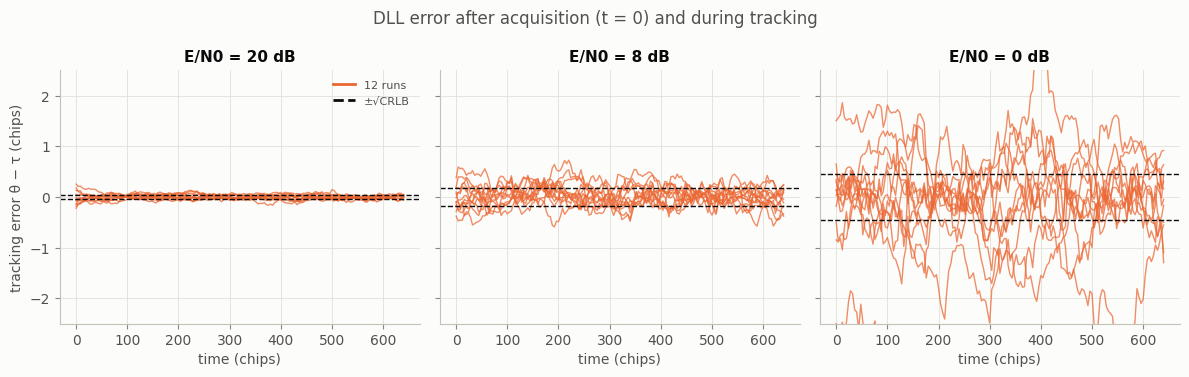

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for a, db in zip(ax, (20, 8, 0)):
    e_ = 10 ** (db / 10)
    tau = sc.draw_delays(12, rng) - sc.tau_c + dll.tau_c
    h = dll.run(tau, sc.sigma2(e_), rng, keep_history=12)["hist"]
    tchips = np.arange(h.shape[1]) * cfg.dll_block_chips
    for row in h:
        a.plot(tchips, row, color=COLORS["dll"], lw=1, alpha=0.75)
    s = np.sqrt(crlb(sc, e_))
    a.axhline(s, color=COLORS["crlb"], ls="--", lw=1); a.axhline(-s, color=COLORS["crlb"], ls="--", lw=1)
    a.set_title(f"E/N0 = {db} dB"); a.set_xlabel("time (chips)")
ax[0].set_ylabel("tracking error θ − τ (chips)"); ax[0].set_ylim(-2.5, 2.5)
ax[0].plot([], [], color=COLORS["dll"], label="12 runs"); ax[0].plot([], [], color=COLORS["crlb"], ls="--", label="±√CRLB")
ax[0].legend(loc="upper right", fontsize=8)
fig.suptitle("DLL error after acquisition (t = 0) and during tracking", color=INK2)
fig.tight_layout(); fig.savefig(FIG + "s2_dll_tracking_run.png")

## 2.6 Steady-state accuracy once locked
4000 runs at three high SNRs; we compare the final MSE with the batch CRLB (± = one Monte Carlo standard error).

In [7]:
# 4000 runs per SNR; the +- is one standard error of the Monte Carlo estimate
for db in (15, 20, 25):
    e_ = 10 ** (db / 10)
    tau = sc.draw_delays(4000, rng) - sc.tau_c + dll.tau_c
    err = dll.run(tau, sc.sigma2(e_), rng)["theta"] - tau
    ratio = err ** 2 / crlb(sc, e_)
    print(f"E/N0 = {db} dB: DLL MSE / batch CRLB = {ratio.mean():.3f} ± {ratio.std() / np.sqrt(ratio.size):.3f}")

E/N0 = 15 dB: DLL MSE / batch CRLB = 1.088 ± 0.025


E/N0 = 20 dB: DLL MSE / batch CRLB = 1.083 ± 0.024


E/N0 = 25 dB: DLL MSE / batch CRLB = 1.039 ± 0.023


## 2.7 Results and what they mean

* **S-curve.** Near zero, $D(\varepsilon)\approx\varepsilon$ (slope 1 by construction), so the loop measures its own
  error correctly. $D$ keeps the correct sign out to about **±1.8 chips** — the pull-in range. Beyond it, the
  discriminator output is almost zero and the loop no longer knows which way to go. This is why an **acquisition**
  stage is needed first, and it is the seed of the DLL's own failure mode (**loss of lock**).
* **Tracking run.** At 20 dB every run locks within a few tens of chips and stays inside ±√CRLB. At 8 dB runs stay
  locked but jitter more. At 0 dB some runs wander off by more than a chip: noise has pushed the error outside the
  S-curve's restoring region — **loss of lock**, a failure mechanism the batch MLE does not have.
* **Steady state.** Once locked, the DLL's MSE is about **1.07 × the batch CRLB**. That closeness is *by design* (we
  chose $K$ so the loop averages ~64 chips). The 7 % excess comes from early–late being only a finite-difference
  approximation of the waveform derivative that an optimal estimator would use. (The exact theory of this number is
  Sprint-5 material; see notebook 05.)

**Why this matters for the next sprints.** Sprint 3 derives the CRLB that both estimators are compared against; the
S-curve and pull-in range explain, in Sprint 6, *why* the DLL's threshold behaves differently from the MLE's.